使用经典的 Iris 鸢尾花数据集学习 PCA

假设有一个数据集，每条鸢尾花样本包含 4 个特征：
- 花萼长度（sepal length）
- 花萼宽度（sepal width）
- 花瓣长度（petal length）
- 花瓣宽度（petal width）

原始数据的每个样本可以表示为： $X_i=[x_1,x_2,x_3,x_4]$


如果希望将 4 维特征压缩为 2 维特征，就可以使用 PCA：$\mathbb{R}^{4}\longrightarrow\mathbb{R}^{2}$

第一个主成分（PC1）是数据方差最大的方向；第二个主成分（PC2）是在与第一个主成分正交的条件下，方差最大的方向。

[sklearn-pca](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html)


In [16]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [22]:
# 0、加载数据
data = load_iris()
X = data.data
y = data.target

print(X.shape, y.shape)
print(data.feature_names)
print(data.target_names)

(150, 4) (150,)
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
['setosa' 'versicolor' 'virginica']


In [8]:
# 1、数据预处理：根据数据特点决定是否使用 StandardScaler 标准化。不同特征的量纲或方差差异较大时，通常建议先标准化。
# 2、中心化数据：对每个特征减去该特征的均值，使其均值变为 0。sklearn 的 PCA 会自动执行中心化。
# 3、寻找主成分方向：通过奇异值分解（SVD）等计算方法确定数据方差最大的方向。
# 4、选择主成分数量：保留前两个主成分，或者设置方差解释率阈值，让 sklearn 自动选择需要保留的维度。
# 5、投影并评估：使用 fit_transform() 得到低维数据，再查看 explained_variance_ratio_ 判断保留了多少方差信息。


"""
算法：使用 PCA 将 Iris 数据从 4 维降到 2 维

输入：
    X：原始数据，形状为 (150, 4)
    k：需要保留的主成分数量，k = 2

输出：
    Z：降维后的数据，形状为 (150, 2)

步骤：
    1. 加载 Iris 数据集，提取 4 个数值特征 X

    2. 对 X 的每一列进行标准化
       让每个特征具有接近 0 的均值和 1 的方差

    3. 计算每个特征的均值
       用每个特征的原始值减去对应均值，完成中心化

    4. 对中心化矩阵执行奇异值分解
       得到主成分方向

    5. 按照方差从大到小排列主成分方向

    6. 选择前 k = 2 个主成分方向

    7. 将原始数据投影到这两个方向
       得到 Z

    8. 计算每个主成分的方差解释率

    9. 绘制 Z 的散点图
       使用 Iris 原始标签 y 区分三种花

    10. 输出降维前后数据的形状和累计方差解释率
"""

In [23]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled

array([[-9.00681170e-01,  1.01900435e+00, -1.34022653e+00,
        -1.31544430e+00],
       [-1.14301691e+00, -1.31979479e-01, -1.34022653e+00,
        -1.31544430e+00],
       [-1.38535265e+00,  3.28414053e-01, -1.39706395e+00,
        -1.31544430e+00],
       [-1.50652052e+00,  9.82172869e-02, -1.28338910e+00,
        -1.31544430e+00],
       [-1.02184904e+00,  1.24920112e+00, -1.34022653e+00,
        -1.31544430e+00],
       [-5.37177559e-01,  1.93979142e+00, -1.16971425e+00,
        -1.05217993e+00],
       [-1.50652052e+00,  7.88807586e-01, -1.34022653e+00,
        -1.18381211e+00],
       [-1.02184904e+00,  7.88807586e-01, -1.28338910e+00,
        -1.31544430e+00],
       [-1.74885626e+00, -3.62176246e-01, -1.34022653e+00,
        -1.31544430e+00],
       [-1.14301691e+00,  9.82172869e-02, -1.28338910e+00,
        -1.44707648e+00],
       [-5.37177559e-01,  1.47939788e+00, -1.28338910e+00,
        -1.31544430e+00],
       [-1.26418478e+00,  7.88807586e-01, -1.22655167e+00,
      

In [24]:
# 计算每个特征的均值
X = pd.DataFrame(X)
print(X.mean())
X_uncenter = X.to_numpy() - X.mean().to_numpy()
X_uncenter

0    5.843333
1    3.057333
2    3.758000
3    1.199333
dtype: float64


array([[-7.43333333e-01,  4.42666667e-01, -2.35800000e+00,
        -9.99333333e-01],
       [-9.43333333e-01, -5.73333333e-02, -2.35800000e+00,
        -9.99333333e-01],
       [-1.14333333e+00,  1.42666667e-01, -2.45800000e+00,
        -9.99333333e-01],
       [-1.24333333e+00,  4.26666667e-02, -2.25800000e+00,
        -9.99333333e-01],
       [-8.43333333e-01,  5.42666667e-01, -2.35800000e+00,
        -9.99333333e-01],
       [-4.43333333e-01,  8.42666667e-01, -2.05800000e+00,
        -7.99333333e-01],
       [-1.24333333e+00,  3.42666667e-01, -2.35800000e+00,
        -8.99333333e-01],
       [-8.43333333e-01,  3.42666667e-01, -2.25800000e+00,
        -9.99333333e-01],
       [-1.44333333e+00, -1.57333333e-01, -2.35800000e+00,
        -9.99333333e-01],
       [-9.43333333e-01,  4.26666667e-02, -2.25800000e+00,
        -1.09933333e+00],
       [-4.43333333e-01,  6.42666667e-01, -2.25800000e+00,
        -9.99333333e-01],
       [-1.04333333e+00,  3.42666667e-01, -2.15800000e+00,
      

In [28]:
# 3. 创建 PCA 模型
# n_components 表示降为后的维度为 2
pca = PCA(n_components=2)

# 学习主成分方向，并将数据转换到低维空间
X_pca = pca.fit_transform(X_scaled)

print("\n降维前数据形状：", X_scaled.shape)
print("降维后数据形状：", X_pca.shape)

# ==================================================
# 4. 查看方差解释率
# ==================================================
print("\n每个主成分的方差解释率：")
print(pca.explained_variance_ratio_)

print("\n累计方差解释率：")
print(pca.explained_variance_ratio_.sum())

# 查看每个主成分由原始特征组成的系数
print("\n主成分方向矩阵：")
print(pca.components_)

# ==================================================
# 5. 整理降维结果
# ==================================================
result_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "species": [
        data.target_names[i] for i in y
    ]
})

print("\n降维后的数据：")
print(result_df.head(10))



降维前数据形状： (150, 4)
降维后数据形状： (150, 2)

每个主成分的方差解释率：
[0.72962445 0.22850762]

累计方差解释率：
0.9581320720000164

主成分方向矩阵：
[[ 0.52106591 -0.26934744  0.5804131   0.56485654]
 [ 0.37741762  0.92329566  0.02449161  0.06694199]]

降维后的数据：
        PC1       PC2 species
0 -2.264703  0.480027  setosa
1 -2.080961 -0.674134  setosa
2 -2.364229 -0.341908  setosa
3 -2.299384 -0.597395  setosa
4 -2.389842  0.646835  setosa
5 -2.075631  1.489178  setosa
6 -2.444029  0.047644  setosa
7 -2.232847  0.223148  setosa
8 -2.334640 -1.115328  setosa
9 -2.184328 -0.469014  setosa


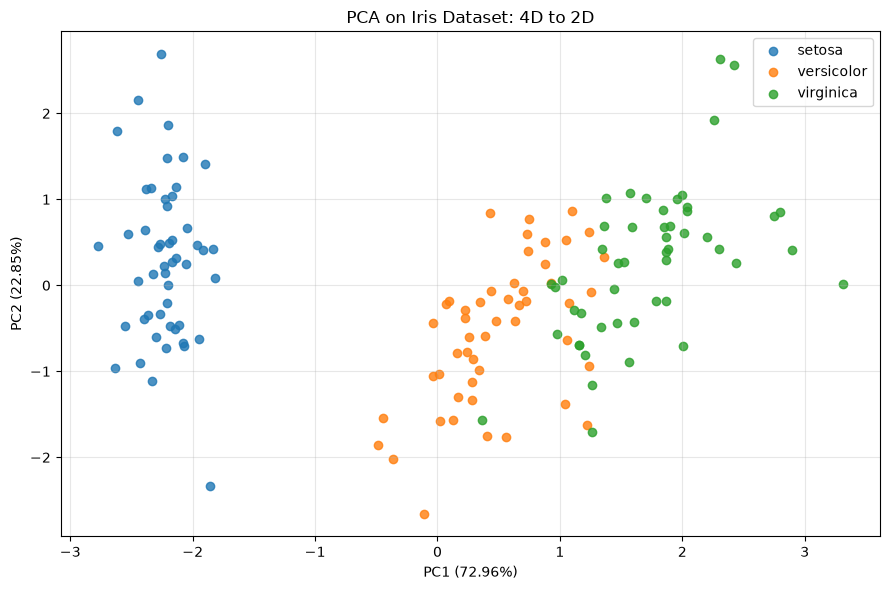

In [30]:
# ==================================================
# 6. 绘制二维散点图
# ==================================================
plt.figure(figsize=(9, 6))

for label, name in enumerate(data.target_names):
    mask = y == label

    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=name,
        alpha=0.8
    )

plt.xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0]:.2%})"
)
plt.ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1]:.2%})"
)
plt.title("PCA on Iris Dataset: 4D to 2D")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


完整的各主成分方差解释率：
[0.72962445 0.22850762 0.03668922 0.00517871]

完整的累计方差解释率：
[0.72962445 0.95813207 0.99482129 1.        ]


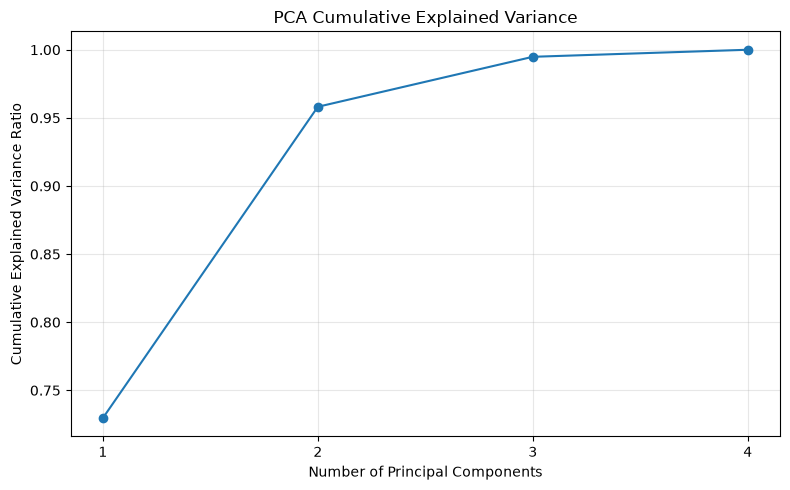

In [31]:
# ==================================================
# 7. 绘制各主成分的累计方差解释率
# ==================================================
# 这里重新拟合 4 个主成分，以观察所有维度的信息量
pca_full = PCA(n_components=4)
pca_full.fit(X_scaled)

ratios = pca_full.explained_variance_ratio_
cumulative_ratios = np.cumsum(ratios)

print("\n完整的各主成分方差解释率：")
print(ratios)

print("\n完整的累计方差解释率：")
print(cumulative_ratios)

plt.figure(figsize=(8, 5))

components = np.arange(1, len(ratios) + 1)

plt.plot(
    components,
    cumulative_ratios,
    marker="o"
)

plt.xticks(components)
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance Ratio")
plt.title("PCA Cumulative Explained Variance")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:

# PCA 中必须掌握的 sklearn API
# API	作用
# PCA(n_components=2)	创建 PCA 模型，保留 2 个主成分
# pca.fit(X)	学习主成分方向
# pca.transform(X)	将数据投影到已经学习的主成分空间
# pca.fit_transform(X)	学习主成分并完成降维
# pca.components_	查看主成分方向系数
# pca.explained_variance_	查看各主成分的方差
# pca.explained_variance_ratio_	查看各主成分的方差解释率
# pca.singular_values_	查看奇异值
# pca.inverse_transform(X_pca)	将低维数据近似还原到原始特征空间

In [34]:

# 进阶：将 PCA 用于真实机器学习模型
# PCA 不仅可以画图，也可以作为其他机器学习模型的预处理步骤，例如：
# 原始特征 → 标准化 → PCA 降维 → LogisticRegression 分类

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score

iris = load_iris()
X, y = iris.data, iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=23,
    stratify=y
)

model = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=2)),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

pred_y = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, pred_y))
print("PCA 保留的方差比例：", model.named_steps["pca"].explained_variance_ratio_.sum())

Accuracy: 0.9
PCA 保留的方差比例： 0.9574419222931336
